In [1]:
import pandas as pd


In [6]:
df = pd.read_excel("online_retail_II.xlsx")

In [7]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[ns]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 32.1+ MB


In [9]:
df.shape

(525461, 8)

In [10]:
df.isnull().sum()

,0
Invoice,0
StockCode,0
Description,2928
Quantity,0
InvoiceDate,0
Price,0
Customer ID,107927
Country,0


In [11]:
df_clean = df.copy()

# Remove rows without Customer ID
df_clean = df_clean.dropna(subset=['Customer ID'])

# Remove rows with missing descriptions
df_clean = df_clean.dropna(subset=['Description'])

# Remove cancelled invoices
df_clean = df_clean[~df_clean['Invoice'].astype(str).str.startswith('C')]

# Keep only positive quantities
df_clean = df_clean[df_clean['Quantity'] > 0]

# Keep only positive prices
df_clean = df_clean[df_clean['Price'] > 0]

# Create total sales for each transaction
df_clean['Sales'] = df_clean['Quantity'] * df_clean['Price']


df_clean.shape

(407664, 9)

In [12]:
df_clean.isnull().sum()

,0
Invoice,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
Price,0
Customer ID,0
Country,0
Sales,0


In [13]:
# Calculate customer-level metrics

customer_metrics = df_clean.groupby('Customer ID').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Orders=('Invoice', 'nunique'),
    Total_Items=('Quantity', 'sum'),
    First_Purchase=('InvoiceDate', 'min'),
    Last_Purchase=('InvoiceDate', 'max')
).reset_index()

# Calculate customer lifespan in days
customer_metrics['Lifespan_Days'] = (
    customer_metrics['Last_Purchase'] -
    customer_metrics['First_Purchase']
).dt.days

# Calculate Average Order Value
customer_metrics['Average_Order_Value'] = (
    customer_metrics['Total_Sales'] /
    customer_metrics['Total_Orders']
)

# View the result
customer_metrics.head()

,Customer ID,Total_Sales,Total_Orders,Total_Items,First_Purchase,Last_Purchase,Lifespan_Days,Average_Order_Value
0,12346.0,372.86,11,70,2009-12-14 08:34:00,2010-06-28 13:53:00,196,33.896364
1,12347.0,1323.32,2,828,2010-10-31 14:20:00,2010-12-07 14:57:00,37,661.660000
2,12348.0,222.16,1,373,2010-09-27 14:59:00,2010-09-27 14:59:00,0,222.160000
3,12349.0,2671.14,3,993,2010-04-29 13:20:00,2010-10-28 08:23:00,181,890.380000
4,12351.0,300.93,1,261,2010-11-29 15:23:00,2010-11-29 15:23:00,0,300.930000


In [14]:
customer_metrics.shape

(4312, 8)

In [15]:
customer_metrics.describe()

,Customer ID,Total_Sales,Total_Orders,Total_Items,First_Purchase,Last_Purchase,Lifespan_Days,Average_Order_Value
count,4312.000000,4312.000000,4312.000000,4312.000000,4312,4312,4312.000000,4312.000000
mean,15349.290353,2048.238236,4.455705,1284.404917,2010-04-29 01:20:08.710575104,2010-09-10 09:08:37.138219008,133.998609,378.322627
min,12346.000000,2.950000,1.000000,1.000000,2009-12-01 07:45:00,2009-12-01 09:55:00,0.000000,2.950000
25%,13882.500000,307.987500,1.000000,158.000000,2010-01-15 11:34:30,2010-07-27 09:53:00,0.000000,182.087857
50%,15350.500000,706.020000,2.000000,382.000000,2010-04-01 08:26:00,2010-10-18 16:34:30,105.000000,287.368056
75%,16834.250000,1723.142500,5.000000,996.250000,2010-08-15 11:15:30,2010-11-22 11:01:30,254.000000,423.576667
max,18287.000000,349164.350000,205.000000,220600.000000,2010-12-09 16:08:00,2010-12-09 20:01:00,373.000000,11880.840000
std,1701.200176,8914.481280,8.170213,6459.164580,NaN,NaN,132.827183,492.564076


In [16]:
# CLV Method 1: Historical CLV

customer_metrics['Historical_CLV'] = customer_metrics['Total_Sales']

# Display customers with highest historical CLV
customer_metrics[
    ['Customer ID', 'Total_Sales', 'Total_Orders', 'Historical_CLV']
].sort_values(
    'Historical_CLV',
    ascending=False
).head(10)

,Customer ID,Total_Sales,Total_Orders,Historical_CLV
4183,18102.0,349164.35,89,349164.35
1637,14646.0,248396.50,78,248396.50
1269,14156.0,196566.74,102,196566.74
1840,14911.0,152147.57,205,152147.57
939,13694.0,131443.19,94,131443.19
3744,17511.0,84541.17,31,84541.17
1951,15061.0,83284.38,86,83284.38
3128,16684.0,80489.21,27,80489.21
3177,16754.0,65500.07,29,65500.07
4065,17949.0,60117.60,74,60117.60


In [17]:
customer_metrics['Historical_CLV'].describe()

,Historical_CLV
count,4312.000000
mean,2048.238236
std,8914.481280
min,2.950000
25%,307.987500
50%,706.020000
75%,1723.142500
max,349164.350000


In [18]:
print("Number of customers:", customer_metrics['Customer ID'].nunique())
print("Average Historical CLV: £", round(customer_metrics['Historical_CLV'].mean(), 2))
print("Median Historical CLV: £", round(customer_metrics['Historical_CLV'].median(), 2))
print("Maximum Historical CLV: £", round(customer_metrics['Historical_CLV'].max(), 2))

Number of customers: 4312
Average Historical CLV: £ 2048.24
Median Historical CLV: £ 706.02
Maximum Historical CLV: £ 349164.35


In [19]:
# Avoid division by zero for customers who purchased on only one day
customer_metrics['Effective_Lifespan_Days'] = (
    customer_metrics['Lifespan_Days'].clip(lower=30)
)

# Purchases per year
customer_metrics['Purchase_Frequency_Yearly'] = (
    customer_metrics['Total_Orders'] /
    customer_metrics['Effective_Lifespan_Days'] * 365
)

customer_metrics[
    ['Customer ID', 'Total_Orders', 'Lifespan_Days',
     'Purchase_Frequency_Yearly']
].head(10)

,Customer ID,Total_Orders,Lifespan_Days,Purchase_Frequency_Yearly
0,12346.0,11,196,20.484694
1,12347.0,2,37,19.729730
2,12348.0,1,0,12.166667
3,12349.0,3,181,6.049724
4,12351.0,1,0,12.166667
5,12352.0,2,16,24.333333
6,12353.0,1,0,12.166667
7,12355.0,1,0,12.166667
8,12356.0,3,44,24.886364
9,12357.0,2,0,24.333333


In [20]:
expected_lifespan_years = 1

customer_metrics['Estimated_CLV'] = (
    customer_metrics['Average_Order_Value'] *
    customer_metrics['Purchase_Frequency_Yearly'] *
    expected_lifespan_years
)

customer_metrics[
    ['Customer ID', 'Average_Order_Value',
     'Purchase_Frequency_Yearly', 'Estimated_CLV']
].head(10)

,Customer ID,Average_Order_Value,Purchase_Frequency_Yearly,Estimated_CLV
0,12346.0,33.896364,20.484694,694.356633
1,12347.0,661.660000,19.729730,13054.372973
2,12348.0,222.160000,12.166667,2702.946667
3,12349.0,890.380000,6.049724,5386.553039
4,12351.0,300.930000,12.166667,3661.315000
5,12352.0,171.900000,24.333333,4182.900000
6,12353.0,317.760000,12.166667,3866.080000
7,12355.0,488.210000,12.166667,5939.888333
8,12356.0,1187.416667,24.886364,29550.482955
9,12357.0,6039.995000,24.333333,146973.211667


In [21]:
customer_metrics['Estimated_CLV'].describe()

,Estimated_CLV
count,4312.000000
mean,5190.276427
std,12513.306327
min,35.891667
25%,1657.139332
50%,2938.310833
75%,5161.951667
max,341675.570375


In [22]:
customer_metrics[
    ['Customer ID', 'Historical_CLV', 'Estimated_CLV']
].sort_values(
    'Estimated_CLV',
    ascending=False
).head(10)

,Customer ID,Historical_CLV,Estimated_CLV
4183,18102.0,349164.35,341675.570375
3704,17450.0,52422.30,273344.850000
1637,14646.0,248396.50,250455.034530
1269,14156.0,196566.74,196029.672404
2444,15760.0,13916.34,169315.470000
1225,14088.0,13544.99,164797.378333
76,12454.0,13151.44,160009.186667
1840,14911.0,152147.57,148884.351340
9,12357.0,12079.99,146973.211667
933,13687.0,11880.84,144550.220000


In [23]:
# Compare the two CLV methods

clv_comparison = customer_metrics[
    ['Customer ID', 'Historical_CLV', 'Estimated_CLV']
].copy()

clv_comparison['CLV_Difference'] = (
    clv_comparison['Estimated_CLV'] -
    clv_comparison['Historical_CLV']
)

clv_comparison.head(10)

,Customer ID,Historical_CLV,Estimated_CLV,CLV_Difference
0,12346.0,372.86,694.356633,321.496633
1,12347.0,1323.32,13054.372973,11731.052973
2,12348.0,222.16,2702.946667,2480.786667
3,12349.0,2671.14,5386.553039,2715.413039
4,12351.0,300.93,3661.315000,3360.385000
5,12352.0,343.80,4182.900000,3839.100000
6,12353.0,317.76,3866.080000,3548.320000
7,12355.0,488.21,5939.888333,5451.678333
8,12356.0,3562.25,29550.482955,25988.232955
9,12357.0,12079.99,146973.211667,134893.221667


In [24]:
print("Average Historical CLV: £", round(
    customer_metrics['Historical_CLV'].mean(), 2
))

print("Average Estimated CLV: £", round(
    customer_metrics['Estimated_CLV'].mean(), 2
))

print("Median Historical CLV: £", round(
    customer_metrics['Historical_CLV'].median(), 2
))

print("Median Estimated CLV: £", round(
    customer_metrics['Estimated_CLV'].median(), 2
))

Average Historical CLV: £ 2048.24
Average Estimated CLV: £ 5190.28
Median Historical CLV: £ 706.02
Median Estimated CLV: £ 2938.31


In [25]:
# Calculate CLV thresholds
low_threshold = customer_metrics['Estimated_CLV'].quantile(0.25)
high_threshold = customer_metrics['Estimated_CLV'].quantile(0.75)

print("Low threshold: £", round(low_threshold, 2))
print("High threshold: £", round(high_threshold, 2))

Low threshold: £ 1657.14
High threshold: £ 5161.95


In [26]:
def assign_segment(clv):
    if clv >= high_threshold:
        return 'High Value'
    elif clv >= low_threshold:
        return 'Medium Value'
    else:
        return 'Low Value'

customer_metrics['Customer_Segment'] = (
    customer_metrics['Estimated_CLV'].apply(assign_segment)
)

customer_metrics[
    ['Customer ID', 'Estimated_CLV', 'Customer_Segment']
].head(10)

,Customer ID,Estimated_CLV,Customer_Segment
0,12346.0,694.356633,Low Value
1,12347.0,13054.372973,High Value
2,12348.0,2702.946667,Medium Value
3,12349.0,5386.553039,High Value
4,12351.0,3661.315000,Medium Value
5,12352.0,4182.900000,Medium Value
6,12353.0,3866.080000,Medium Value
7,12355.0,5939.888333,High Value
8,12356.0,29550.482955,High Value
9,12357.0,146973.211667,High Value


In [27]:
segment_summary = customer_metrics.groupby('Customer_Segment').agg(
    Customer_Count=('Customer ID', 'count'),
    Average_CLV=('Estimated_CLV', 'mean'),
    Total_CLV=('Estimated_CLV', 'sum'),
    Average_Order_Value=('Average_Order_Value', 'mean')
).reset_index()

segment_summary

,Customer_Segment,Customer_Count,Average_CLV,Total_CLV,Average_Order_Value
0,High Value,1078,13537.384653,1.459330e+07,730.644523
1,Low Value,1078,1047.730354,1.129453e+06,166.111088
2,Medium Value,2156,3087.995351,6.657718e+06,308.267449


In [28]:
customer_metrics['Customer_Segment'].value_counts()

,count
Customer_Segment,
Medium Value,2156
Low Value,1078
High Value,1078


In [29]:
final_clv_table = customer_metrics[
    [
        'Customer ID',
        'Total_Sales',
        'Total_Orders',
        'Total_Items',
        'First_Purchase',
        'Last_Purchase',
        'Lifespan_Days',
        'Average_Order_Value',
        'Purchase_Frequency_Yearly',
        'Historical_CLV',
        'Estimated_CLV',
        'Customer_Segment'
    ]
].copy()

final_clv_table.head()

,Customer ID,Total_Sales,Total_Orders,Total_Items,First_Purchase,Last_Purchase,Lifespan_Days,Average_Order_Value,Purchase_Frequency_Yearly,Historical_CLV,Estimated_CLV,Customer_Segment
0,12346.0,372.86,11,70,2009-12-14 08:34:00,2010-06-28 13:53:00,196,33.896364,20.484694,372.86,694.356633,Low Value
1,12347.0,1323.32,2,828,2010-10-31 14:20:00,2010-12-07 14:57:00,37,661.660000,19.729730,1323.32,13054.372973,High Value
2,12348.0,222.16,1,373,2010-09-27 14:59:00,2010-09-27 14:59:00,0,222.160000,12.166667,222.16,2702.946667,Medium Value
3,12349.0,2671.14,3,993,2010-04-29 13:20:00,2010-10-28 08:23:00,181,890.380000,6.049724,2671.14,5386.553039,High Value
4,12351.0,300.93,1,261,2010-11-29 15:23:00,2010-11-29 15:23:00,0,300.930000,12.166667,300.93,3661.315000,Medium Value


In [30]:
final_clv_table[
    ['Total_Sales', 'Average_Order_Value',
     'Historical_CLV', 'Estimated_CLV']
] = final_clv_table[
    ['Total_Sales', 'Average_Order_Value',
     'Historical_CLV', 'Estimated_CLV']
].round(2)

In [31]:
with pd.ExcelWriter('Customer_CLV_Analysis.xlsx', engine='openpyxl') as writer:

    # Main customer CLV table
    final_clv_table.to_excel(
        writer,
        sheet_name='Customer CLV',
        index=False
    )

    # Segment summary
    segment_summary.to_excel(
        writer,
        sheet_name='Segment Analysis',
        index=False
    )

    # Assumptions
    assumptions = pd.DataFrame({
        'Assumption': [
            'Cancelled invoices are excluded',
            'Transactions without Customer ID are excluded',
            'Transactions with non-positive quantity are excluded',
            'Transactions with non-positive price are excluded',
            'Historical CLV equals total historical sales',
            'Estimated CLV assumes observed purchasing frequency continues for one year',
            'Estimated CLV is an approximate estimate and not a guarantee of future behavior'
        ]
    })

    assumptions.to_excel(
        writer,
        sheet_name='Assumptions',
        index=False
    )

print("Excel file created successfully!")

Excel file created successfully!


In [32]:
from google.colab import files

files.download('Customer_CLV_Analysis.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

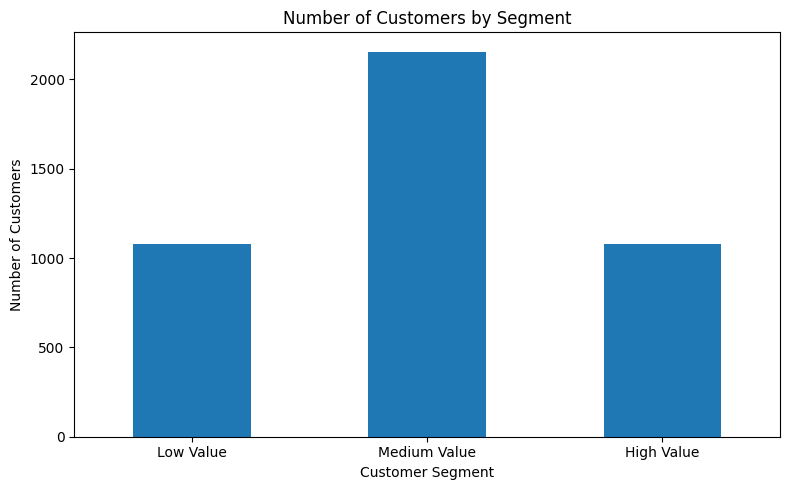

In [33]:
import matplotlib.pyplot as plt

segment_counts = (
    customer_metrics['Customer_Segment']
    .value_counts()
    .reindex(['Low Value', 'Medium Value', 'High Value'])
)

plt.figure(figsize=(8, 5))
segment_counts.plot(kind='bar')

plt.title('Number of Customers by Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

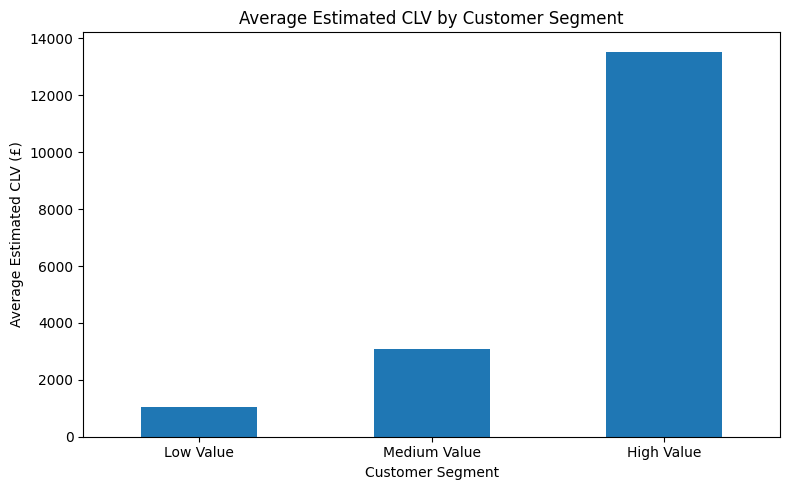

In [34]:
average_clv = (
    customer_metrics
    .groupby('Customer_Segment')['Estimated_CLV']
    .mean()
    .reindex(['Low Value', 'Medium Value', 'High Value'])
)

plt.figure(figsize=(8, 5))
average_clv.plot(kind='bar')

plt.title('Average Estimated CLV by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Average Estimated CLV (£)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [35]:
print("===== KEY FINDINGS =====")

print("Total customers:", len(customer_metrics))

print(
    "Average Historical CLV: £",
    round(customer_metrics['Historical_CLV'].mean(), 2)
)

print(
    "Average Estimated CLV: £",
    round(customer_metrics['Estimated_CLV'].mean(), 2)
)

print(
    "\nCustomers by segment:"
)

print(customer_metrics['Customer_Segment'].value_counts())

print(
    "\nAverage CLV by segment:"
)

print(
    customer_metrics
    .groupby('Customer_Segment')['Estimated_CLV']
    .mean()
    .round(2)
)

===== KEY FINDINGS =====
Total customers: 4312
Average Historical CLV: £ 2048.24
Average Estimated CLV: £ 5190.28

Customers by segment:
Customer_Segment
Medium Value    2156
Low Value       1078
High Value      1078
Name: count, dtype: int64

Average CLV by segment:
Customer_Segment
High Value      13537.38
Low Value        1047.73
Medium Value     3088.00
Name: Estimated_CLV, dtype: float64
